# Anomaly Detection in Credit Card Transactions

Unsupervised detection of rare fraudulent card payments. The models in this notebook never train on the fraud label.

The dataset is the ULB Machine Learning Group credit-card file published on Kaggle (284,807 transactions). Each row is one transaction. `V1`–`V28` are principal components of the original (confidential) features. `Time` is seconds since the first transaction in the file. `Amount` is the payment size in euros. `Class` is 1 for fraud and 0 for a legitimate payment.

**Rule for this project:** `Class` is hidden from training. It is used only to measure how many of the flagged rows are real frauds.

## Contents

1. Setup
2. Load the data and hold the label aside
3. Data exploration
4. Preprocessing
5. PCA and t-SNE (visualization only)
6. Unsupervised models
7. Evaluation with the hidden labels
8. What the flagged transactions look like
9. Conclusions
10. References

Run the cells from top to bottom. A full run usually takes several minutes. The One-Class SVM cell is the slow one.


## 1. Setup

The constants below are the whole experimental design.

- `ALERT_RATE = 0.002` means a reviewer looks at about 0.2% of transactions. It is fixed **before** any model scores are inspected, so it is not tuned to maximize F1 on the labels.
- The classic RBF One-Class SVM cannot be fit on all 280,000 rows in reasonable time or memory, so it is fit on `RBF_TRAIN_ROWS` rows. The other two models use the full fit slice.
- `RUN_TSNE` can be set to `False` if you want to skip that plot.


In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import OneClassSVM
import sklearn

RANDOM_STATE = 42
ALERT_RATE = 0.002
TEST_FRACTION = 0.20
CAL_FRACTION = 0.10

RBF_TRAIN_ROWS = 5000
SVM_NU = 0.05

IF_TREES = 200
IF_MAX_SAMPLES = 8192
IF_N_JOBS = -1  # set to 1 if Windows raises a parallel-processing error

AE_HIDDEN = (24, 8, 24)
AE_EPOCHS = 25
AE_BATCH = 1024

RUN_TSNE = True
TSNE_ROWS = 2000
VIZ_ROWS = 4000
NL = chr(10)

FIG_DIR = Path('figures')
RESULT_DIR = Path('results')
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

print('numpy', np.__version__)
print('pandas', pd.__version__)
print('scikit-learn', sklearn.__version__)
print(f'Alert rate (fixed): {ALERT_RATE:.1%}')
print(f'Random state: {RANDOM_STATE}')


def finish_plot(filename: str) -> None:
    path = FIG_DIR / filename
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()
    print(f'Saved {path.as_posix()}')


def slug(name: str) -> str:
    cleaned = ''.join(ch.lower() if ch.isalnum() else '_' for ch in name)
    return '_'.join(part for part in cleaned.split('_') if part)


def print_frame(frame: pd.DataFrame, digits: int = 3) -> None:
    formatted = frame.copy()
    for col in formatted.columns:
        if pd.api.types.is_float_dtype(formatted[col]):
            formatted[col] = formatted[col].map(
                lambda v, d=digits: '' if pd.isna(v) else f'{v:.{d}f}'
            )
    print(formatted.to_string(index=False))


def apply_cutoff(cal_scores, test_scores, rate: float):
    # Higher score = more anomalous. The cutoff is the top `rate` of calibration scores.
    cutoff = float(np.quantile(cal_scores, 1.0 - rate))
    test_flags = (test_scores >= cutoff).astype(int)
    print(f'Cutoff: {cutoff:.6f}')
    print(f'Calibration rows at or above cutoff: {(cal_scores >= cutoff).mean():.3%}')
    print(f'Test rows at or above cutoff: {test_flags.mean():.3%}')
    return cutoff, test_flags


def scatter_colored(z, values, title, filename, color_label, axis_prefix):
    fig, ax = plt.subplots(figsize=(7.2, 5.4))
    points = ax.scatter(z[:, 0], z[:, 1], c=values, s=8, cmap='magma', alpha=0.75)
    fig.colorbar(points, ax=ax, label=color_label)
    ax.set_title(title)
    ax.set_xlabel(f'{axis_prefix} 1')
    ax.set_ylabel(f'{axis_prefix} 2')
    finish_plot(filename)


def locate_dataset() -> Path:
    candidates = [
        Path.cwd() / 'data' / 'creditcard.csv',
        Path.cwd() / 'creditcard.csv',
        Path('data') / 'creditcard.csv',
    ]
    for path in candidates:
        if path.exists():
            return path.resolve()
    searched = NL.join(f'  - {path.resolve()}' for path in candidates)
    message = NL.join([
        'creditcard.csv was not found.',
        'Download Credit Card Fraud Detection from',
        'https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud',
        'and save it as data/creditcard.csv in this project folder.',
        'Looked in:',
        searched,
    ])
    raise FileNotFoundError(message)


numpy 2.5.5
pandas 3.1.1
scikit-learn 1.9.1
Alert rate (fixed): 0.2%
Random state: 42


## 2. Load the data and hold the label aside

Exact duplicate rows are removed so the same transaction cannot land in both the fit slice and the test set. After that, `Class` is copied to `y` and is not part of the feature table. Every later `fit` call receives features only.


In [2]:
DATA_PATH = locate_dataset()
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f'Loaded {DATA_PATH}')

expected = ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount', 'Class']
missing = [col for col in expected if col not in df.columns]
if missing:
    raise ValueError(f'Unexpected file. Missing columns: {missing}')

raw_rows = len(df)
print(f'Rows in the file: {raw_rows:,}')
print(f'Columns: {df.shape[1]}')
print(f'Missing values: {int(df.isna().sum().sum()):,}')
print(f'Exact duplicate rows: {int(df.duplicated().sum()):,}')

df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows after dropping exact duplicates: {len(df):,}')

V_COLS = [f'V{i}' for i in range(1, 29)]
y = df['Class'].to_numpy(dtype=int)
if not set(np.unique(y)).issubset({0, 1}):
    raise ValueError('Class should contain only 0 and 1.')

print(df.drop(columns=['Class']).head(3).to_string())
print('Label column held aside:', 'Class')


Loaded C:\Users\MB\Desktop\Anomoly Detection\data\creditcard.csv
Rows in the file: 284,807
Columns: 31
Missing values: 0
Exact duplicate rows: 1,081
Rows after dropping exact duplicates: 283,726
   Time        V1        V2        V3        V4        V5        V6        V7        V8        V9       V10       V11       V12       V13       V14       V15       V16       V17       V18       V19       V20       V21       V22       V23       V24       V25       V26       V27       V28  Amount
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599  0.098698  0.363787  0.090794 -0.551600 -0.617801 -0.991390 -0.311169  1.468177 -0.470401  0.207971  0.025791  0.403993  0.251412 -0.018307  0.277838 -0.110474  0.066928  0.128539 -0.189115  0.133558 -0.021053  149.62
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803  0.085102 -0.255425 -0.166974  1.612727  1.065235  0.489095 -0.143772  0.635558  0.463917 -0.114805 -0.183361 -0.145783 -0.069083 -0.22

## 3. Data exploration

Questions for this section:

- How skewed is `Amount`?
- Does `Time` cover a daily cycle, or only a single burst?
- Are `V1`–`V28` redundant copies of each other?
- How rare is fraud? The count is shown so the later metrics make sense. It is not passed into any model.


            Time     Amount
count  283726.00  283726.00
mean    94811.08      88.47
std     47481.05     250.40
min         0.00       0.00
25%     54204.75       5.60
50%     84692.50      22.00
75%    139298.00      77.51
max    172792.00   25691.16
Amount skewness: 16.98
log1p(Amount) skewness: 0.16
Time runs from 0 to 48.0 hours


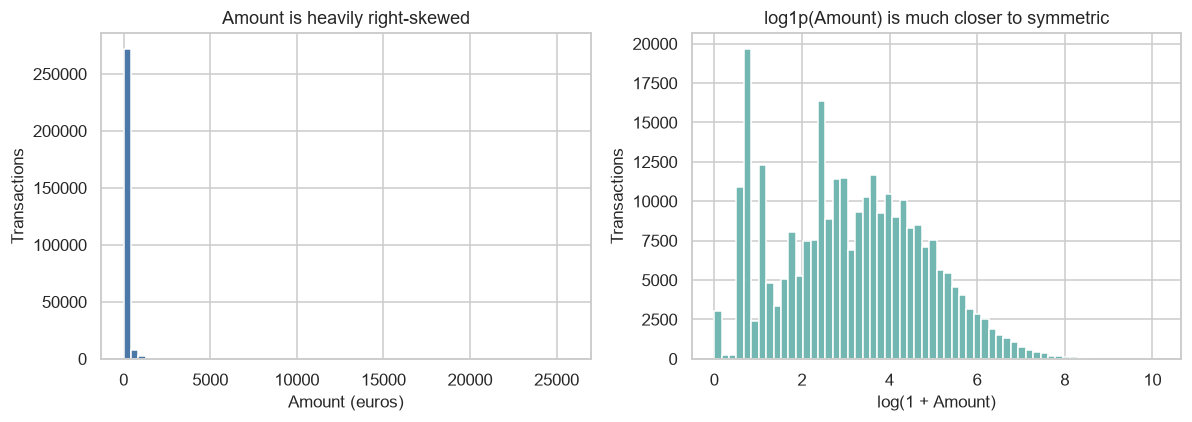

Saved figures/01_amount_distribution.png


In [3]:
print(df[['Time', 'Amount']].describe().round(2).to_string())
print(f'Amount skewness: {df["Amount"].skew():.2f}')
print(f'log1p(Amount) skewness: {np.log1p(df["Amount"]).skew():.2f}')
print(f'Time runs from 0 to {df["Time"].max() / 3600:.1f} hours')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df['Amount'], bins=60, color='#4C78A8')
axes[0].set_title('Amount is heavily right-skewed')
axes[0].set_xlabel('Amount (euros)')
axes[0].set_ylabel('Transactions')
axes[1].hist(np.log1p(df['Amount']), bins=60, color='#72B7B2')
axes[1].set_title('log1p(Amount) is much closer to symmetric')
axes[1].set_xlabel('log(1 + Amount)')
axes[1].set_ylabel('Transactions')
finish_plot('01_amount_distribution.png')


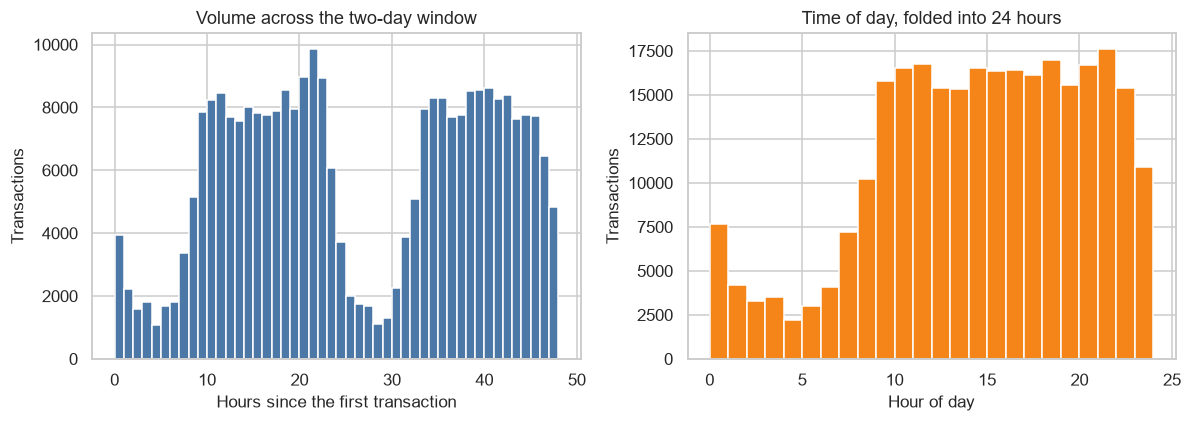

Saved figures/02_time_distribution.png


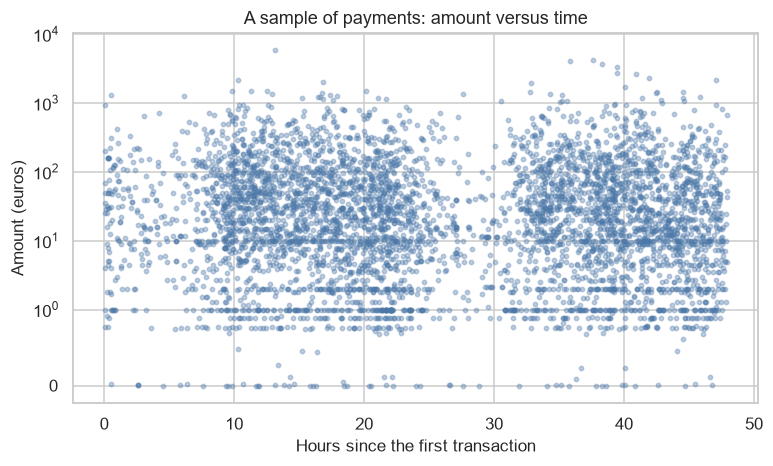

Saved figures/03_amount_vs_time.png


In [4]:
hour_all = (df['Time'].to_numpy() % (24 * 3600)) / 3600.0

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df['Time'] / 3600.0, bins=48, color='#4C78A8')
axes[0].set_title('Volume across the two-day window')
axes[0].set_xlabel('Hours since the first transaction')
axes[0].set_ylabel('Transactions')
axes[1].hist(hour_all, bins=24, color='#F58518')
axes[1].set_title('Time of day, folded into 24 hours')
axes[1].set_xlabel('Hour of day')
axes[1].set_ylabel('Transactions')
finish_plot('02_time_distribution.png')

sample_idx = np.random.default_rng(RANDOM_STATE).choice(len(df), size=5000, replace=False)
sample = df.iloc[sample_idx]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.scatter(sample['Time'] / 3600.0, sample['Amount'].clip(lower=0), s=8, alpha=0.35, c='#4C78A8')
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('Hours since the first transaction')
ax.set_ylabel('Amount (euros)')
ax.set_title('A sample of payments: amount versus time')
finish_plot('03_amount_vs_time.png')


Largest absolute correlation among V1-V28: 0.0189
These columns are nearly uncorrelated, which is what principal components should look like.


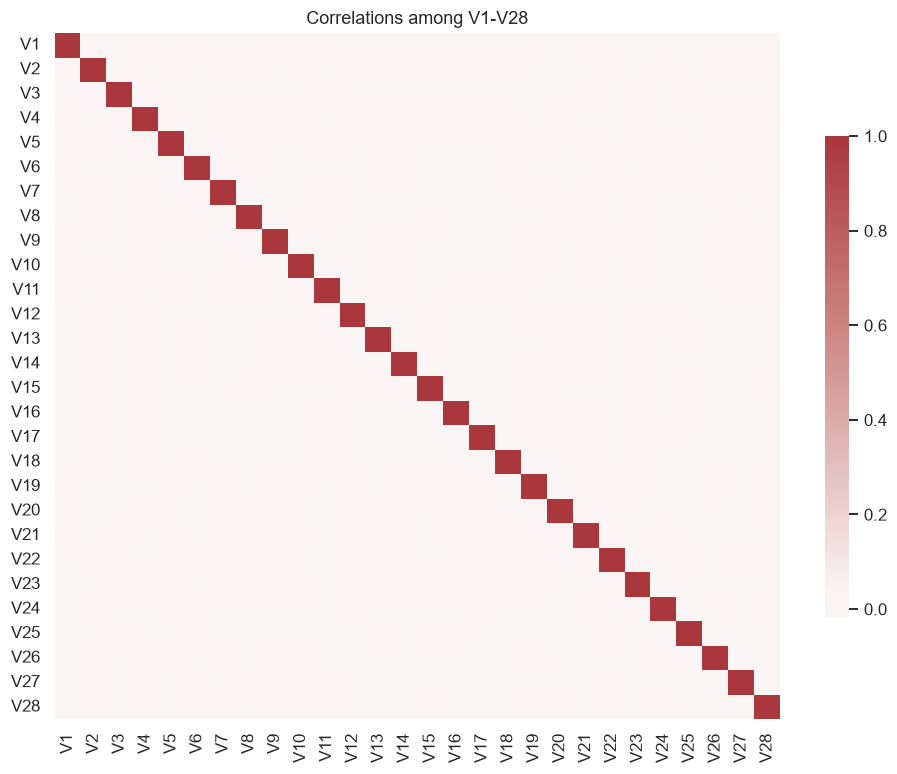

Saved figures/04_v_correlation.png


In [7]:
v_corr = df[V_COLS].corr().to_numpy(copy=True)
np.fill_diagonal(v_corr, 0.0)
print(f'Largest absolute correlation among V1-V28: {np.nanmax(np.abs(v_corr)):.4f}')
print('These columns are nearly uncorrelated, which is what principal components should look like.')

fig, ax = plt.subplots(figsize=(9, 7.2))
sns.heatmap(
    df[V_COLS].corr(),
    cmap='vlag',
    center=0,
    xticklabels=True,
    yticklabels=True,
    ax=ax,
    cbar_kws={'shrink': 0.7},
)
ax.set_title('Correlations among V1-V28')
finish_plot('04_v_correlation.png')


Legitimate: 283,253
Fraud: 473 (0.167% of rows)
This chart is the imbalance check. The models do not receive these labels.
A classifier that called every row legitimate would be about 99.8% accurate and would catch nothing.


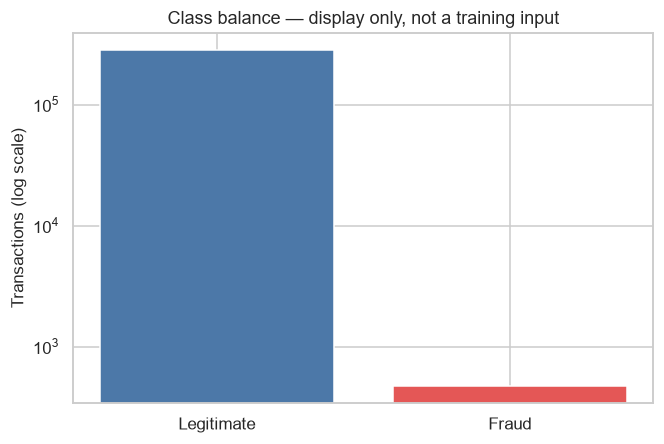

Saved figures/05_class_balance.png


In [8]:
n_legit = int((y == 0).sum())
n_fraud = int((y == 1).sum())
print(f'Legitimate: {n_legit:,}')
print(f'Fraud: {n_fraud:,} ({n_fraud / len(y):.3%} of rows)')
print('This chart is the imbalance check. The models do not receive these labels.')
print('A classifier that called every row legitimate would be about 99.8% accurate and would catch nothing.')

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.bar(['Legitimate', 'Fraud'], [n_legit, n_fraud], color=['#4C78A8', '#E45756'])
ax.set_yscale('log')
ax.set_ylabel('Transactions (log scale)')
ax.set_title('Class balance — display only, not a training input')
finish_plot('05_class_balance.png')


## 4. Preprocessing

**Features**

- `V1`–`V28` kept as published. They are already principal components.
- `log1p(Amount)` instead of raw amount, because a few large payments would otherwise dominate the scale.
- `Time` kept, so the model can tell the two days apart.
- `Hour_sin` and `Hour_cos` encode the hour of day as a circle (23:00 and 00:00 stay next to each other).

**Scaling.** `MinMaxScaler` is fit on the fit slice only, then applied to the calibration slice and the test set. Fitting on the whole file would leak test-set ranges into training.

**Why scale the V columns too?** One-Class SVM and the autoencoder treat every column as a number on a shared scale. Raw `Time` (tens of thousands) would drown `V1` (mostly single digits) if we left them alone. The tradeoff: min-max scaling compresses extreme V values, and extremes are where anomalies live. Isolation Forest is less sensitive to that compression because it splits on order rather than distance. The same scaled matrix is used for all three models so the comparison is about the model, not about a private preprocessing trick.

**Split, without using `Class`.**

- 20% of rows go to the test set, untouched until evaluation.
- Of the remaining 80%, the last 10% is the calibration slice. It sets the alert cutoff only. It is not used to fit the model.
- The other 90% of the training rows are the fit slice.

The permutation is random, not stratified. Stratifying would use the label to balance the split.


In [9]:
hour = (df['Time'].to_numpy() % (24 * 3600)) / 3600.0
feature_frame = pd.DataFrame(
    {
        **{col: df[col].to_numpy() for col in V_COLS},
        'Amount_log': np.log1p(df['Amount'].to_numpy()),
        'Time': df['Time'].to_numpy(),
        'Hour_sin': np.sin(2 * np.pi * hour / 24.0),
        'Hour_cos': np.cos(2 * np.pi * hour / 24.0),
    }
)
assert 'Class' not in feature_frame.columns
FEATURE_NAMES = list(feature_frame.columns)
X_all = feature_frame.to_numpy(dtype=np.float64)

order = np.random.default_rng(RANDOM_STATE).permutation(len(df))
n_train = int((1.0 - TEST_FRACTION) * len(df))
train_pos = order[:n_train]
test_pos = order[n_train:]
n_cal = int(CAL_FRACTION * len(train_pos))
fit_pos = train_pos[:-n_cal]
cal_pos = train_pos[-n_cal:]

if len(fit_pos) <= RBF_TRAIN_ROWS:
    raise RuntimeError('The fit slice is smaller than RBF_TRAIN_ROWS. Lower RBF_TRAIN_ROWS.')

scaler = MinMaxScaler()
X_fit = np.ascontiguousarray(scaler.fit_transform(X_all[fit_pos]), dtype=np.float64)
X_cal = np.ascontiguousarray(scaler.transform(X_all[cal_pos]), dtype=np.float64)
X_test = np.ascontiguousarray(scaler.transform(X_all[test_pos]), dtype=np.float64)

if not np.isfinite(X_fit).all():
    raise ValueError('Fit features contain NaN or infinity.')

amount_test = df['Amount'].to_numpy()[test_pos]
time_test = df['Time'].to_numpy()[test_pos]
hour_test = (time_test % (24 * 3600)) / 3600.0

print(f'Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}')
print(f'Fit rows: {len(X_fit):,}')
print(f'Calibration rows: {len(X_cal):,}')
print(f'Test rows: {len(X_test):,}')
print('Scaler was fit on the fit rows only.')
print(f'Scaled minimum (fit): {X_fit.min():.3f}   maximum (fit): {X_fit.max():.3f}')

score_bank = {}
flag_bank = {}
cutoff_bank = {}


Features (32): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log', 'Time', 'Hour_sin', 'Hour_cos']
Fit rows: 204,282
Calibration rows: 22,698
Test rows: 56,746
Scaler was fit on the fit rows only.
Scaled minimum (fit): 0.000   maximum (fit): 1.000


## 5. PCA and t-SNE (visualization only)

These pictures are not model inputs. `V1`–`V28` are already a PCA of the confidential banking fields, so a second PCA is only a way to look at the table. Two axes will leave a lot of variance unexplained. A blob in the scatter does **not** mean there is nothing to detect: fraud in this file is a thin tail in 30 dimensions, not a separate island.

t-SNE is fit on a random sample of test rows for the picture only. It has no stable `transform` step and is never fed to Isolation Forest, the SVM, or the autoencoder.


Variance kept by 2 components: 62.6%
Components needed to pass 90% of variance: 7


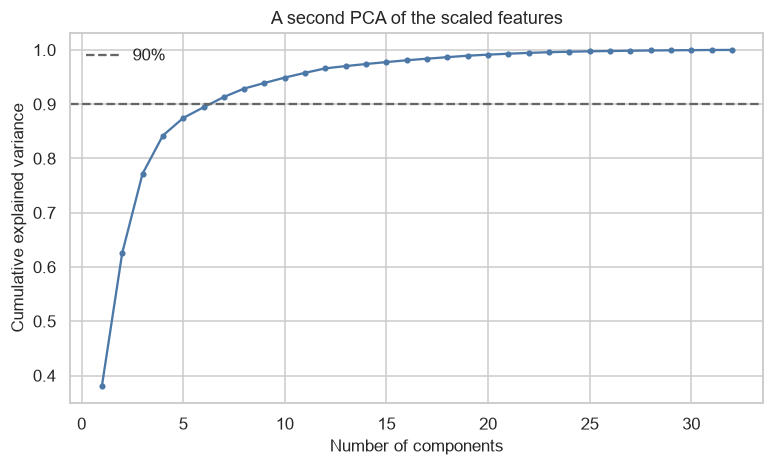

Saved figures/06_pca_variance.png


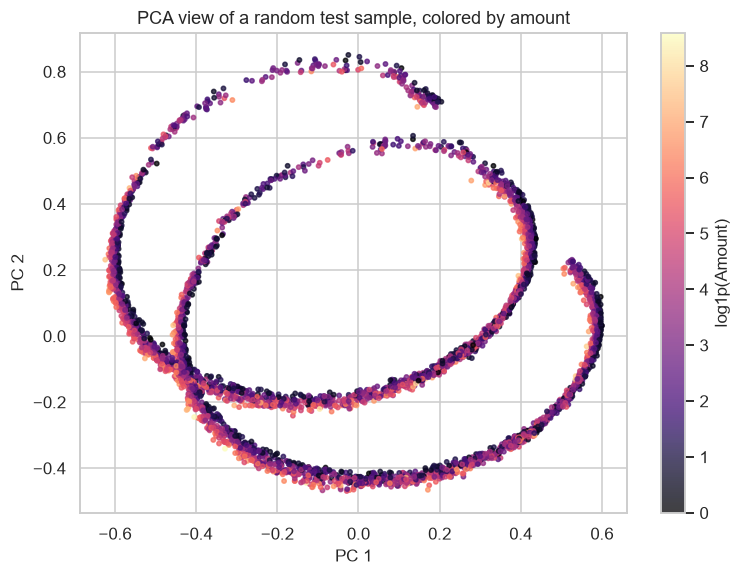

Saved figures/07_pca_amount.png
t-SNE finished in 4.4s on 2,000 points


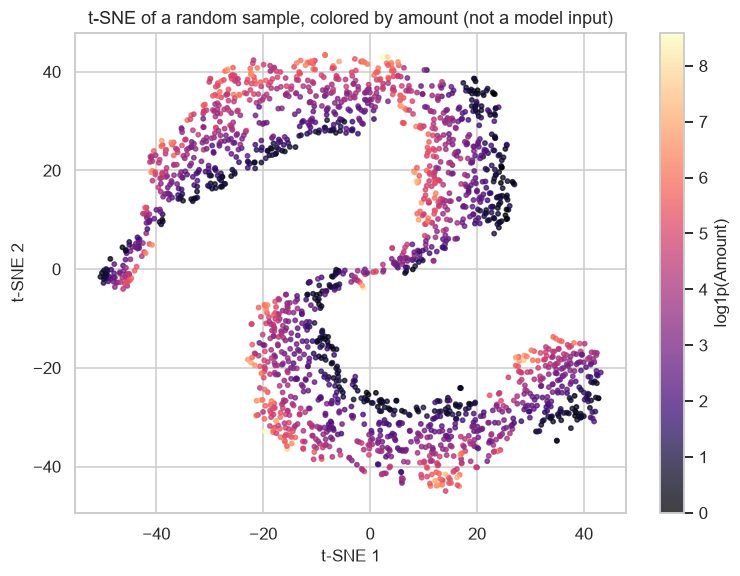

Saved figures/08_tsne_amount.png


In [10]:
pca_all = PCA(random_state=RANDOM_STATE).fit(X_fit)
cumulative = np.cumsum(pca_all.explained_variance_ratio_)
print(f'Variance kept by 2 components: {cumulative[1]:.1%}')
print(f'Components needed to pass 90% of variance: {int(np.searchsorted(cumulative, 0.90) + 1)}')

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative, marker='o', ms=3, color='#4C78A8')
ax.axhline(0.90, color='0.4', ls='--', label='90%')
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative explained variance')
ax.set_title('A second PCA of the scaled features')
ax.legend(frameon=False)
finish_plot('06_pca_variance.png')

viz_idx = np.random.default_rng(RANDOM_STATE + 7).choice(
    len(X_test), size=min(VIZ_ROWS, len(X_test)), replace=False
)
Z_pca = pca_all.transform(X_test[viz_idx])[:, :2]
scatter_colored(
    Z_pca,
    np.log1p(amount_test[viz_idx]),
    'PCA view of a random test sample, colored by amount',
    '07_pca_amount.png',
    'log1p(Amount)',
    'PC',
)

Z_tsne = None
tsne_idx = viz_idx[: min(TSNE_ROWS, len(viz_idx))]
if RUN_TSNE:
    started = time.perf_counter()
    reduced = PCA(n_components=10, random_state=RANDOM_STATE).fit(X_fit).transform(X_test[tsne_idx])
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        init='pca',
        learning_rate='auto',
        random_state=RANDOM_STATE,
    )
    Z_tsne = tsne.fit_transform(reduced)
    print(f't-SNE finished in {time.perf_counter() - started:.1f}s on {len(tsne_idx):,} points')
    scatter_colored(
        Z_tsne,
        np.log1p(amount_test[tsne_idx]),
        't-SNE of a random sample, colored by amount (not a model input)',
        '08_tsne_amount.png',
        'log1p(Amount)',
        't-SNE',
    )
else:
    print('RUN_TSNE is False, so the t-SNE plot was skipped.')


## 6. Unsupervised models

All three models rank transactions. A higher score means more unusual. None of them is given `Class`.

They share one alert rule. On the calibration slice we take the score at the top 0.2%. That cutoff is frozen, then applied to the test set. Test labels are still untouched in this section, so the prints below are only about score distributions.

| Model | What the score means | What it is fit on |
| --- | --- | --- |
| Isolation Forest | How fast random trees isolate the point | All fit rows |
| One-Class SVM (RBF) | How far the point sits outside the dense region | 5,000 fit rows |
| Autoencoder | Mean squared reconstruction error | All fit rows, target = the same features |

`nu=0.05` on the SVM is an optimizer setting: up to 5% of its fit rows may sit outside the boundary while the boundary is drawn. It is **not** the review budget. The review budget stays at 0.2% for every model.


### 6.1 Isolation Forest

The forest picks a feature and a random split value, over and over. A legitimate point sits in a crowd, so it takes many splits to end up alone. An unusual point is isolated quickly. The score averages that idea over `IF_TREES` trees. `max_samples` limits how many rows each tree sees; 8,192 is large enough to describe the cloud and much faster than using every row in every tree.


Isolation Forest fit in 1.5s
Cutoff: 0.589816
Calibration rows at or above cutoff: 0.203%
Test rows at or above cutoff: 0.211%


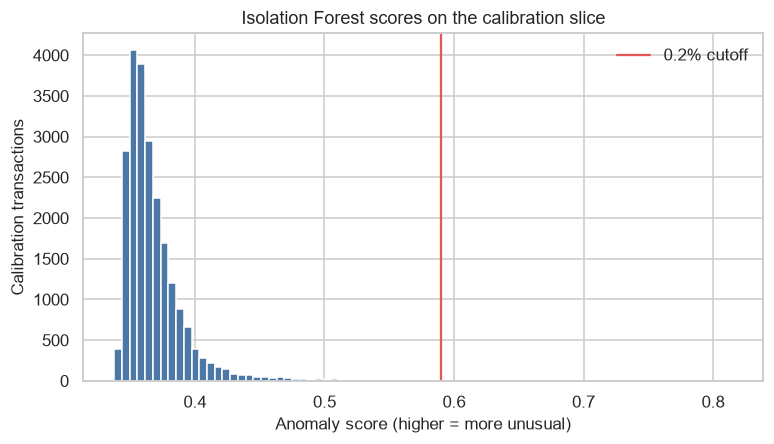

Saved figures/09_iforest_scores.png


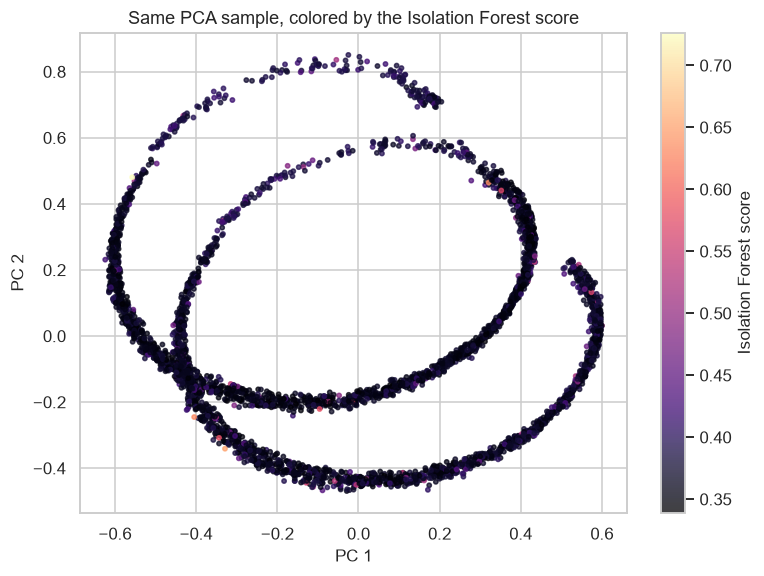

Saved figures/10_pca_iforest_score.png


In [11]:
started = time.perf_counter()
iso = IsolationForest(
    n_estimators=IF_TREES,
    max_samples=IF_MAX_SAMPLES,
    random_state=RANDOM_STATE,
    n_jobs=IF_N_JOBS,
)
iso.fit(X_fit)  # labels are not an argument
print(f'Isolation Forest fit in {time.perf_counter() - started:.1f}s')

if_cal = -iso.score_samples(X_cal)
if_test = -iso.score_samples(X_test)
if_cutoff, if_flags = apply_cutoff(if_cal, if_test, ALERT_RATE)

score_bank['Isolation Forest'] = if_test
flag_bank['Isolation Forest'] = if_flags
cutoff_bank['Isolation Forest'] = if_cutoff

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(if_cal, bins=80, color='#4C78A8')
ax.axvline(if_cutoff, color='#E45756', label='0.2% cutoff')
ax.set_xlabel('Anomaly score (higher = more unusual)')
ax.set_ylabel('Calibration transactions')
ax.set_title('Isolation Forest scores on the calibration slice')
ax.legend(frameon=False)
finish_plot('09_iforest_scores.png')

scatter_colored(
    Z_pca,
    if_test[viz_idx],
    'Same PCA sample, colored by the Isolation Forest score',
    '10_pca_iforest_score.png',
    'Isolation Forest score',
    'PC',
)


### 6.2 One-Class SVM

A one-class SVM puts a boundary around the crowded part of the feature space. Points outside the boundary score as anomalies. The RBF kernel lets that boundary curve.

The textbook solver (`sklearn.svm.OneClassSVM`) builds a kernel against the training rows. On the full fit slice that is too slow and too large for a laptop, so the model is fit on the first 5,000 fit rows. Those rows are a random sample, because the fit rows were shuffled. The cutoff still comes from the full calibration slice, which this SVM did not train on.

The next cell prints progress while it scores the calibration and test rows. Expect a few minutes.


One-Class SVM fit on 5,000 rows in 0.1s
Support vectors: 257
Scoring the calibration slice...
  scored 8,000 / 22,698
  scored 16,000 / 22,698
  scored 22,698 / 22,698
Scoring the test set...
  scored 8,000 / 56,746
  scored 16,000 / 56,746
  scored 24,000 / 56,746
  scored 32,000 / 56,746
  scored 40,000 / 56,746
  scored 48,000 / 56,746
  scored 56,000 / 56,746
  scored 56,746 / 56,746
Cutoff: 22.453902
Calibration rows at or above cutoff: 0.203%
Test rows at or above cutoff: 0.203%


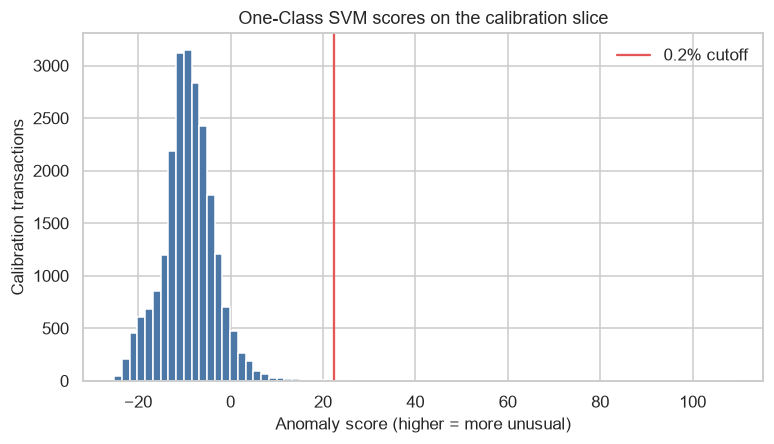

Saved figures/11_svm_scores.png


In [12]:
started = time.perf_counter()
ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=SVM_NU, cache_size=200)
ocsvm.fit(X_fit[:RBF_TRAIN_ROWS])  # labels are not an argument
print(f'One-Class SVM fit on {RBF_TRAIN_ROWS:,} rows in {time.perf_counter() - started:.1f}s')
print(f'Support vectors: {ocsvm.support_vectors_.shape[0]:,}')


def svm_scores(matrix, batch_size=8000):
    parts = []
    for start in range(0, len(matrix), batch_size):
        batch = matrix[start : start + batch_size]
        # decision_function is positive for inliers. Negate it so high = anomalous.
        parts.append(-ocsvm.decision_function(batch))
        done = min(start + batch_size, len(matrix))
        print(f'  scored {done:,} / {len(matrix):,}')
    return np.concatenate(parts)


print('Scoring the calibration slice...')
svm_cal = svm_scores(X_cal)
print('Scoring the test set...')
svm_test = svm_scores(X_test)
svm_cutoff, svm_flags = apply_cutoff(svm_cal, svm_test, ALERT_RATE)

score_bank['One-Class SVM'] = svm_test
flag_bank['One-Class SVM'] = svm_flags
cutoff_bank['One-Class SVM'] = svm_cutoff

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(svm_cal, bins=80, color='#4C78A8')
ax.axvline(svm_cutoff, color='#E45756', label='0.2% cutoff')
ax.set_xlabel('Anomaly score (higher = more unusual)')
ax.set_ylabel('Calibration transactions')
ax.set_title('One-Class SVM scores on the calibration slice')
ax.legend(frameon=False)
finish_plot('11_svm_scores.png')


### 6.3 Autoencoder

The network reads a transaction, squeezes it through a bottleneck of 8 units, and tries to write the same transaction back out:

`inputs → 24 → 8 → 24 → outputs`

The input width is the number of features printed in the preprocessing cell (the V components plus amount, time, and the two hour features).

Training uses the features as both the input and the target (`fit(X_fit, X_fit)`). No label is involved. Almost every fit row is a normal payment, so the bottleneck spends its capacity on normal patterns. A row the network cannot rebuild gets a large mean squared error, and that error is the anomaly score.

This is a small multilayer perceptron used as an autoencoder (`MLPRegressor`), which keeps the project on scikit-learn. A deeper network in PyTorch would be the same idea with more capacity. The internal early-stopping slice only decides when to stop training. The alert cutoff is still the calibration-slice quantile.


Autoencoder fit in 5.9s
Epochs run: 22
Training loss: 0.000906
Cutoff: 0.013542
Calibration rows at or above cutoff: 0.203%
Test rows at or above cutoff: 0.192%


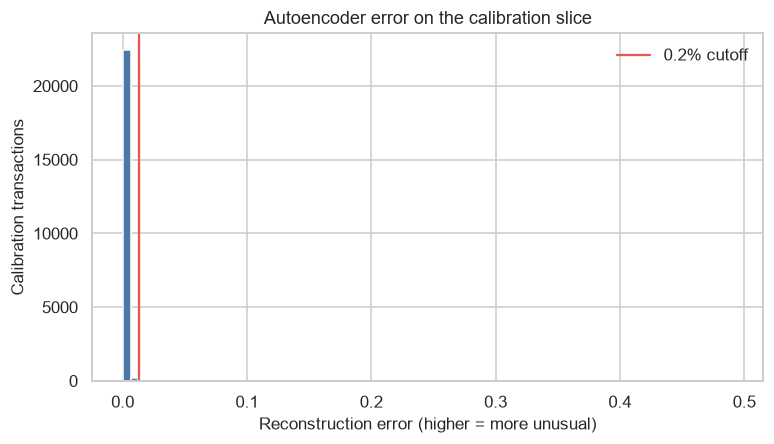

Saved figures/12_autoencoder_errors.png


In [13]:
import warnings
from sklearn.exceptions import ConvergenceWarning

started = time.perf_counter()
autoencoder = MLPRegressor(
    hidden_layer_sizes=AE_HIDDEN,
    activation='relu',
    solver='adam',
    batch_size=AE_BATCH,
    learning_rate_init=0.001,
    max_iter=AE_EPOCHS,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=RANDOM_STATE,
)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    autoencoder.fit(X_fit, X_fit)  # reconstruct the features; labels are not an argument
print(f'Autoencoder fit in {time.perf_counter() - started:.1f}s')
print(f'Epochs run: {autoencoder.n_iter_}')
print(f'Training loss: {autoencoder.loss_:.6f}')


def reconstruction_error(matrix) -> np.ndarray:
    rebuilt = autoencoder.predict(matrix)
    return np.mean((matrix - rebuilt) ** 2, axis=1)


ae_cal = reconstruction_error(X_cal)
ae_test = reconstruction_error(X_test)
ae_cutoff, ae_flags = apply_cutoff(ae_cal, ae_test, ALERT_RATE)

score_bank['Autoencoder'] = ae_test
flag_bank['Autoencoder'] = ae_flags
cutoff_bank['Autoencoder'] = ae_cutoff

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(ae_cal, bins=80, color='#4C78A8')
ax.axvline(ae_cutoff, color='#E45756', label='0.2% cutoff')
ax.set_xlabel('Reconstruction error (higher = more unusual)')
ax.set_ylabel('Calibration transactions')
ax.set_title('Autoencoder error on the calibration slice')
ax.legend(frameon=False)
finish_plot('12_autoencoder_errors.png')


## 7. Evaluation with the hidden labels

This is the first section that scores predictions against `Class`.

For each model the test flags were already decided by the calibration cutoff. We now count:

- **Precision** — share of flags that are real frauds.
- **Recall** — share of real frauds that were flagged.
- **F1** — the harmonic mean of precision and recall, at this fixed budget.
- **Average precision** — area under the precision-recall curve. It does not depend on the 0.2% cutoff. A model that ranks at random lands near the fraud rate in the test set.
- **ROC-AUC** — reported because it is familiar, and easy to over-read. A high ROC-AUC can sit next to a long list of false alarms when the positive class is this rare.

Accuracy is omitted on purpose. Predicting legitimate for every row is about 99.8% accurate and detects no fraud.

The dot on the precision-recall curve is the pre-specified 0.2% budget. Other points on the curve would mean reviewing more or fewer transactions. Choosing the point with the best F1 after seeing this plot would tune the system on the labels, so that point is not the result we claim.


In [14]:
y_test = y[test_pos]
if len(np.unique(y_test)) < 2:
    raise RuntimeError('The test split has only one class. Change RANDOM_STATE and run again.')
if len(score_bank) < 3:
    raise RuntimeError('Train all three models before this cell.')

print(f'Test transactions: {len(y_test):,}')
print(f'Frauds in the test set: {int(y_test.sum()):,} ({y_test.mean():.3%})')
print(f'Chance average precision: {y_test.mean():.4f}')


def evaluate_model(name: str, test_scores, test_flags) -> dict:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        test_flags,
        average='binary',
        pos_label=1,
        zero_division=0,
    )
    matrix = confusion_matrix(y_test, test_flags, labels=[0, 1])
    caught = int(matrix[1, 1])
    frauds = int(y_test.sum())
    return {
        'model': name,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1),
        'average_precision': float(average_precision_score(y_test, test_scores)),
        'roc_auc': float(roc_auc_score(y_test, test_scores)),
        'alert_rate': float(np.mean(test_flags)),
        'flagged': int(np.sum(test_flags)),
        'frauds_in_test': frauds,
        'frauds_caught': caught,
        'frauds_missed': frauds - caught,
        'confusion_matrix': matrix,
    }


records = []
cms = {}
for name in score_bank:
    row = evaluate_model(name, score_bank[name], flag_bank[name])
    cms[name] = row.pop('confusion_matrix')
    records.append(row)

metrics_df = pd.DataFrame(records)
print_frame(metrics_df, digits=4)

for name in flag_bank:
    print()
    print(name)
    print(
        classification_report(
            y_test,
            flag_bank[name],
            target_names=['legitimate', 'fraud'],
            digits=3,
            zero_division=0,
        )
    )


Test transactions: 56,746
Frauds in the test set: 84 (0.148%)
Chance average precision: 0.0015
           model precision recall     f1 average_precision roc_auc alert_rate  flagged  frauds_in_test  frauds_caught  frauds_missed
Isolation Forest    0.2167 0.3095 0.2549            0.2588  0.9659     0.0021      120              84             26             58
   One-Class SVM    0.2957 0.4048 0.3417            0.3004  0.9343     0.0020      115              84             34             50
     Autoencoder    0.2936 0.3810 0.3316            0.2432  0.9590     0.0019      109              84             32             52

Isolation Forest
              precision    recall  f1-score   support

  legitimate      0.999     0.998     0.999     56662
       fraud      0.217     0.310     0.255        84

    accuracy                          0.997     56746
   macro avg      0.608     0.654     0.627     56746
weighted avg      0.998     0.997     0.998     56746


One-Class SVM
             

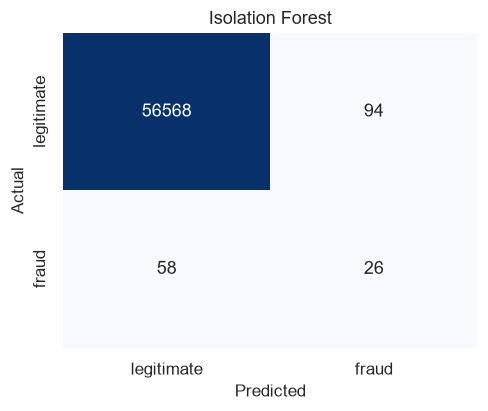

Saved figures/13_cm_isolation_forest.png


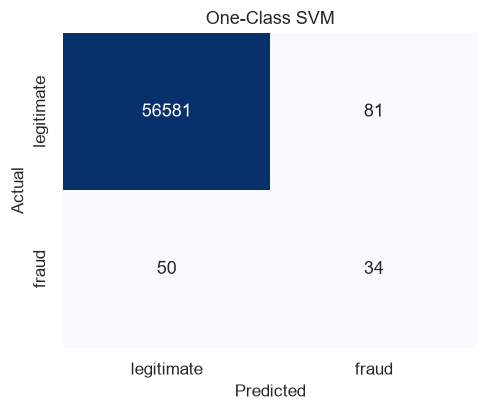

Saved figures/13_cm_one_class_svm.png


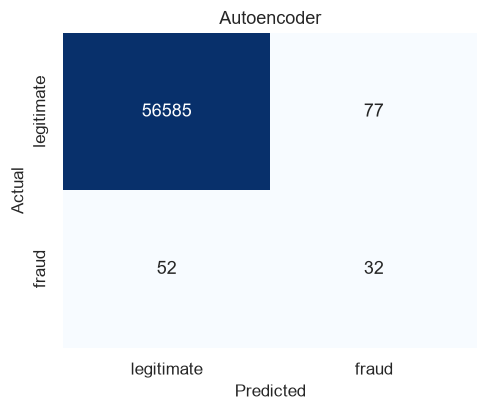

Saved figures/13_cm_autoencoder.png


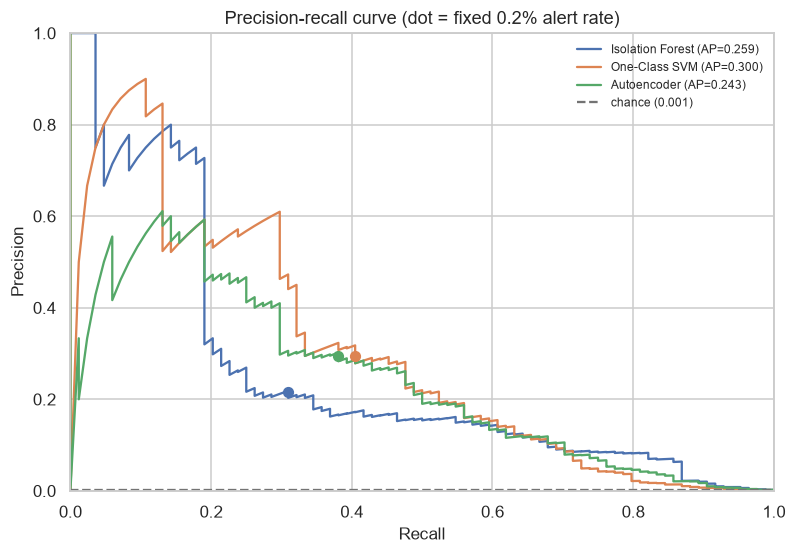

Saved figures/14_precision_recall.png


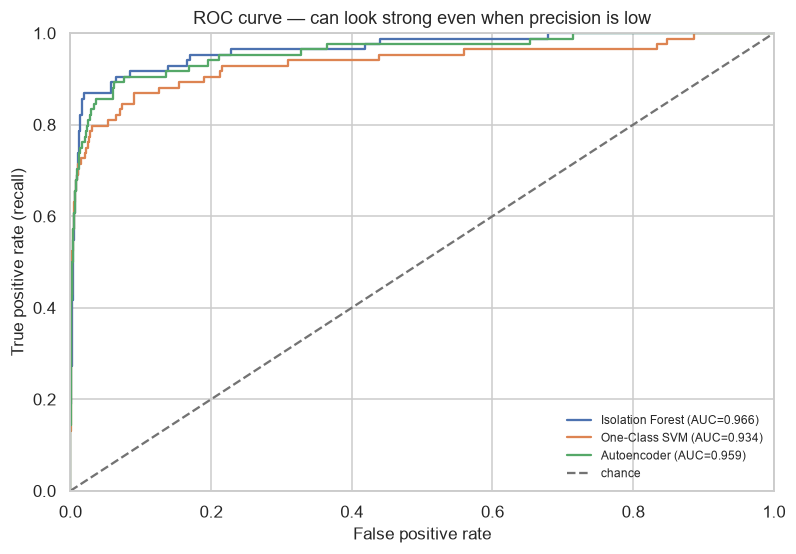

Saved figures/15_roc.png


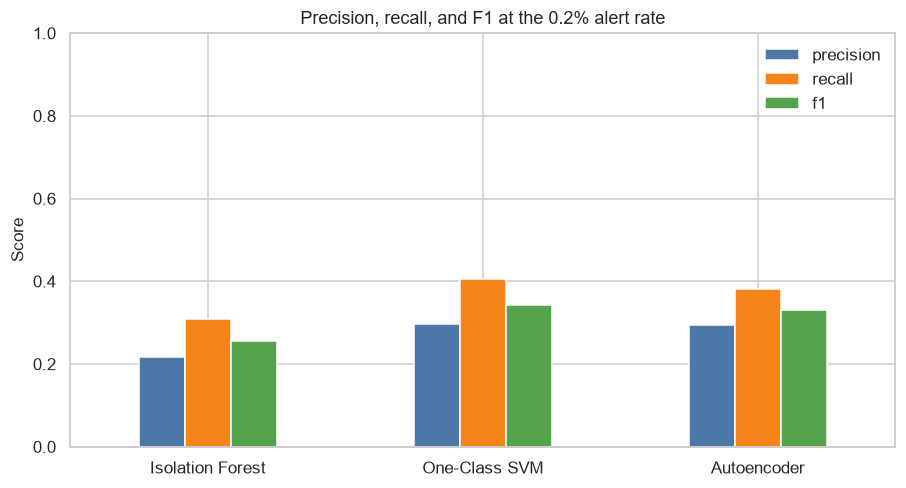

Saved figures/16_metric_bars.png


In [15]:
for name, matrix in cms.items():
    fig, ax = plt.subplots(figsize=(4.6, 3.9))
    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['legitimate', 'fraud'],
        yticklabels=['legitimate', 'fraud'],
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(name)
    finish_plot(f'13_cm_{slug(name)}.png')

fig, ax = plt.subplots(figsize=(7.4, 5.2))
for name in score_bank:
    precision, recall, _ = precision_recall_curve(y_test, score_bank[name])
    ap = average_precision_score(y_test, score_bank[name])
    (line,) = ax.plot(recall, precision, label=f'{name} (AP={ap:.3f})')
    operating = metrics_df.loc[metrics_df['model'] == name].iloc[0]
    ax.scatter(
        [operating['recall']],
        [operating['precision']],
        s=40,
        color=line.get_color(),
        zorder=3,
    )
ax.axhline(y_test.mean(), color='0.45', ls='--', label=f'chance ({y_test.mean():.3f})')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-recall curve (dot = fixed 0.2% alert rate)')
ax.legend(frameon=False, fontsize=8)
finish_plot('14_precision_recall.png')

fig, ax = plt.subplots(figsize=(7.4, 5.2))
for name in score_bank:
    fpr, tpr, _ = roc_curve(y_test, score_bank[name])
    auc = roc_auc_score(y_test, score_bank[name])
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], ls='--', color='0.45', label='chance')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curve — can look strong even when precision is low')
ax.legend(frameon=False, fontsize=8)
finish_plot('15_roc.png')

ax = metrics_df.set_index('model')[['precision', 'recall', 'f1']].plot(
    kind='bar',
    figsize=(8.4, 4.6),
    rot=0,
    color=['#4C78A8', '#F58518', '#54A24B'],
)
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_xlabel('')
ax.set_title('Precision, recall, and F1 at the 0.2% alert rate')
ax.legend(frameon=False)
finish_plot('16_metric_bars.png')


## 8. What the flagged transactions look like

The original merchant, country, and card number are not in this file. A type of transaction here means the amount, the hour, and which anonymized components move.

Read the tables in this order:

1. Profile of everyone, of true frauds, and of each model's flags (median amount, high amounts, hour, and the fraud rate inside the flags — that fraud rate is the precision).
2. How many test rows were flagged by one model, two models, or all three. Agreement is a check on stability. A fraud found by only one model is a softer finding.
3. The 15 test rows with the highest Isolation Forest score.
4. Amount bins: does the forest only catch large payments?
5. Which `V` components differ for true fraud, and do the flags move the same way?

The component chart is the pattern check. If the red and blue bars point the same way, the model is marking the same directions that separate fraud from legitimate payments. Those directions still contain unusual legitimate payments, which is why precision is not 1.


In [17]:
def profile(title: str, mask) -> dict:
    mask = np.asarray(mask, dtype=bool)
    if mask.sum() == 0:
        return {
            'group': title,
            'count': 0,
            'median_amount': np.nan,
            'p95_amount': np.nan,
            'median_hour': np.nan,
            'fraud_rate': np.nan,
        }
    return {
        'group': title,
        'count': int(mask.sum()),
        'median_amount': float(np.median(amount_test[mask])),
        'p95_amount': float(np.quantile(amount_test[mask], 0.95)),
        'median_hour': float(np.median(hour_test[mask])),
        'fraud_rate': float(y_test[mask].mean()),
    }


profile_rows = [
    profile('all test transactions', np.ones(len(y_test), dtype=bool)),
    profile('true fraud', y_test == 1),
]
for name, flags in flag_bank.items():
    profile_rows.append(profile(f'flagged by {name}', flags == 1))

print('Group profiles on the test set')
print_frame(pd.DataFrame(profile_rows), digits=3)

flag_matrix = np.column_stack([flag_bank[name] for name in flag_bank])
n_models_flagged = flag_matrix.sum(axis=1)
print()
print('Test rows by how many models flagged them')
for count in range(0, flag_matrix.shape[1] + 1):
    mask = n_models_flagged == count
    print(
        f'  {count} model(s): {int(mask.sum()):,} transactions, '
        f'of which {int(y_test[mask].sum()):,} are fraud'
    )

print()
print('Overlap of the flags (Jaccard)')
names = list(flag_bank)
for left in range(len(names)):
    for right in range(left + 1, len(names)):
        a = flag_bank[names[left]].astype(bool)
        b = flag_bank[names[right]].astype(bool)
        union = int(np.sum(a | b))
        inter = int(np.sum(a & b))
        score = inter / union if union else 0.0
        print(f'  {names[left]} vs {names[right]}: Jaccard {score:.3f} ({inter:,} shared flags)')


Group profiles on the test set
                      group  count median_amount p95_amount median_hour fraud_rate
      all test transactions  56746        21.645    365.577      14.963      0.001
                 true fraud     84         7.075    349.060      11.978      1.000
flagged by Isolation Forest    120       135.365   5456.643      12.583      0.217
   flagged by One-Class SVM    115       125.300   5664.278      11.936      0.296
     flagged by Autoencoder    109       109.900   5435.886      12.488      0.294

Test rows by how many models flagged them
  0 model(s): 56,602 transactions, of which 48 are fraud
  1 model(s): 30 transactions, of which 6 are fraud
  2 model(s): 28 transactions, of which 4 are fraud
  3 model(s): 86 transactions, of which 26 are fraud

Overlap of the flags (Jaccard)
  Isolation Forest vs One-Class SVM: Jaccard 0.691 (96 shared flags)
  Isolation Forest vs Autoencoder: Jaccard 0.696 (94 shared flags)
  One-Class SVM vs Autoencoder: Jaccard 0.750 

Highest Isolation Forest scores in the test set (true_class is revealed here)
amount_eur   hour hours_from_start if_score  true_class  isolation_forest  one_class_svm  autoencoder
     2.280  4.143           28.142    0.771           1                 1              1            1
     1.630  2.544           26.544    0.755           1                 1              1            1
    30.310  2.078           26.078    0.753           1                 1              1            1
  3552.960 16.770           40.770    0.753           0                 1              1            1
     1.000  6.017            6.017    0.753           1                 1              1            1
  1676.600 13.812           37.812    0.751           0                 1              1            1
     1.000  5.681            5.681    0.749           1                 1              1            1
    59.680 11.474           11.474    0.749           1                 1              1            1
    

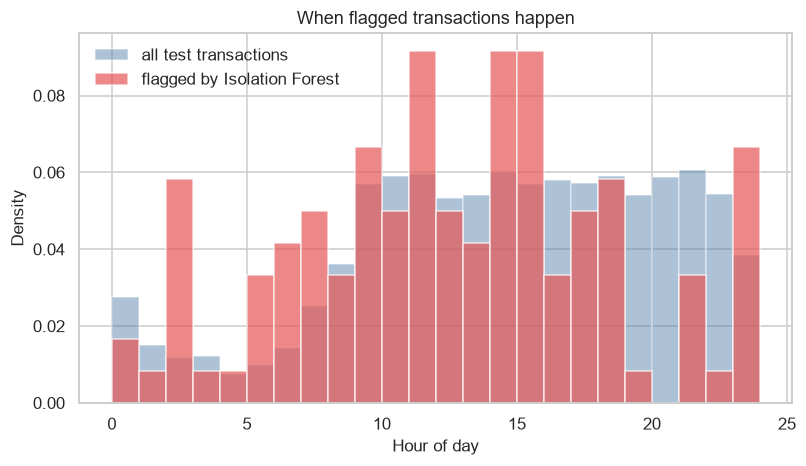

Saved figures/17_flagged_by_hour.png


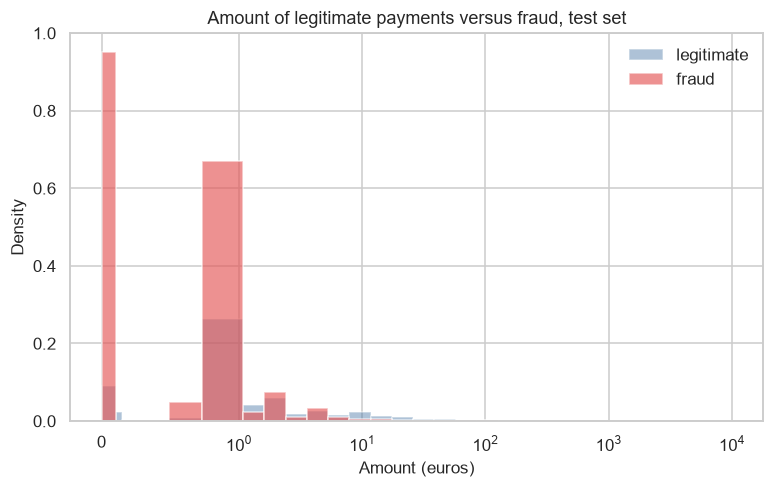

Saved figures/18_amount_by_class.png


In [18]:
top_n = 15
top_order = np.argsort(score_bank['Isolation Forest'])[::-1][:top_n]
top = pd.DataFrame(
    {
        'amount_eur': amount_test[top_order],
        'hour': hour_test[top_order],
        'hours_from_start': time_test[top_order] / 3600.0,
        'if_score': score_bank['Isolation Forest'][top_order],
        'true_class': y_test[top_order],
    }
)
for name, flags in flag_bank.items():
    top[slug(name)] = flags[top_order]

print('Highest Isolation Forest scores in the test set (true_class is revealed here)')
print_frame(top, digits=3)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
bins = np.arange(0, 25, 1)
ax.hist(hour_test, bins=bins, density=True, alpha=0.45, label='all test transactions', color='#4C78A8')
if_flagged_hours = hour_test[flag_bank['Isolation Forest'] == 1]
if len(if_flagged_hours) > 0:
    ax.hist(
        if_flagged_hours,
        bins=bins,
        density=True,
        alpha=0.7,
        label='flagged by Isolation Forest',
        color='#E45756',
    )
ax.set_xlabel('Hour of day')
ax.set_ylabel('Density')
ax.set_title('When flagged transactions happen')
ax.legend(frameon=False)
finish_plot('17_flagged_by_hour.png')

fig, ax = plt.subplots(figsize=(7.2, 4.6))
legit = y_test == 0
fraud = y_test == 1
amount_bins_plot = np.concatenate([[0], np.logspace(-1, 4, 30)])
ax.hist(
    amount_test[legit],
    bins=amount_bins_plot,
    density=True,
    alpha=0.45,
    label='legitimate',
    color='#4C78A8',
)
ax.hist(
    amount_test[fraud],
    bins=amount_bins_plot,
    density=True,
    alpha=0.65,
    label='fraud',
    color='#E45756',
)
ax.set_xscale('symlog', linthresh=1)
ax.set_xlabel('Amount (euros)')
ax.set_ylabel('Density')
ax.set_title('Amount of legitimate payments versus fraud, test set')
ax.legend(frameon=False)
finish_plot('18_amount_by_class.png')


Isolation Forest by amount bin (test set)
amount_eur  transactions  frauds  if_flags  frauds_caught recall_in_bin
       0-1          6052      29        19             12         0.414
      1-10         13968      15        15              3         0.200
     10-50         18166      11        10              2         0.182
    50-100          7426      10        13              7         0.700
   100-500          9303      16        25              2         0.125
      500+          1831       3        38              0         0.000

Do the flags move along the same V components as true fraud?
  Isolation Forest: correlation of V-shifts with true fraud = 0.531
  One-Class SVM: correlation of V-shifts with true fraud = 0.627
  Autoencoder: correlation of V-shifts with true fraud = 0.613


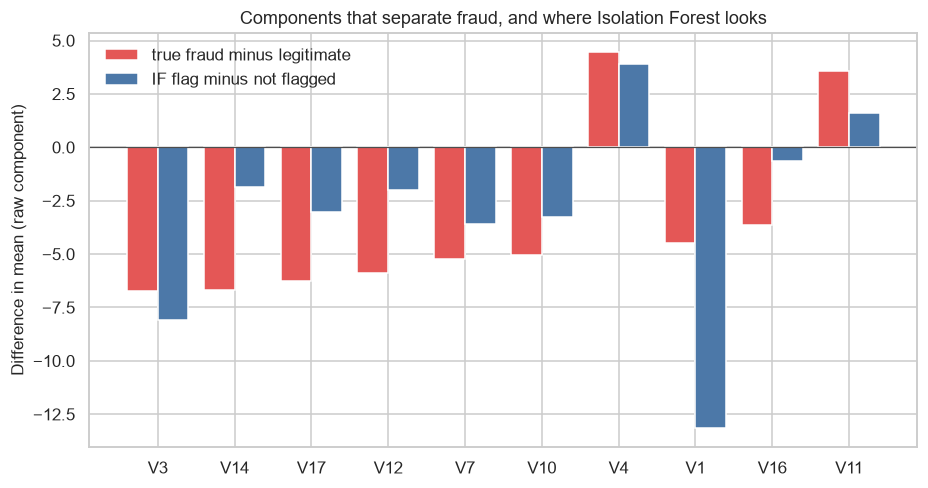

Saved figures/19_component_shift.png


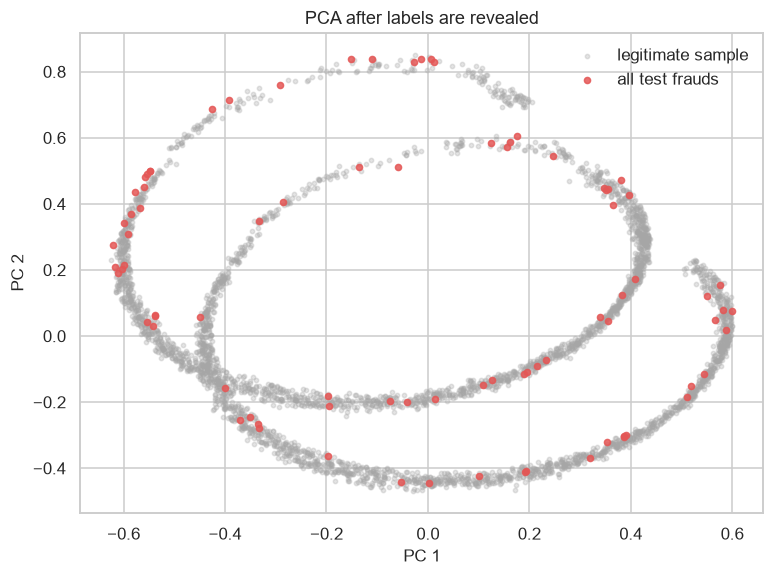

Saved figures/20_pca_with_labels.png
If frauds sit inside the main cloud here, they differ on components this 2D view collapsed.


In [20]:
amount_bins = [0, 1, 10, 50, 100, 500, np.inf]
amount_labels = ['0-1', '1-10', '10-50', '50-100', '100-500', '500+']
binned = pd.cut(amount_test, bins=amount_bins, labels=amount_labels, include_lowest=True)
if_flag = flag_bank['Isolation Forest'] == 1

bin_rows = []
for label in amount_labels:
    mask = np.asarray(binned == label)
    frauds = int(y_test[mask].sum())
    caught = int(np.sum(mask & if_flag & (y_test == 1)))
    bin_rows.append(
        {
            'amount_eur': label,
            'transactions': int(mask.sum()),
            'frauds': frauds,
            'if_flags': int(np.sum(mask & if_flag)),
            'frauds_caught': caught,
            'recall_in_bin': (caught / frauds) if frauds else np.nan,
        }
    )
print('Isolation Forest by amount bin (test set)')
print_frame(pd.DataFrame(bin_rows), digits=3)

V_test = df[V_COLS].to_numpy()[test_pos]


def mean_shift(mask) -> np.ndarray:
    mask = np.asarray(mask, dtype=bool)
    if mask.sum() == 0 or (~mask).sum() == 0:
        return np.full(V_test.shape[1], np.nan)
    return V_test[mask].mean(axis=0) - V_test[~mask].mean(axis=0)


fraud_shift = mean_shift(y_test == 1)
print()
print('Do the flags move along the same V components as true fraud?')
for name, flags in flag_bank.items():
    shift = mean_shift(flags == 1)
    if np.isnan(shift).any() or np.isnan(fraud_shift).any():
        print(f'  {name}: not enough rows to compare')
        continue
    if np.std(fraud_shift) == 0 or np.std(shift) == 0:
        print(f'  {name}: V-shifts have no spread, so there is nothing to correlate')
        continue
    alignment = float(np.corrcoef(fraud_shift, shift)[0, 1])
    print(f'  {name}: correlation of V-shifts with true fraud = {alignment:.3f}')

focus = np.argsort(np.abs(fraud_shift))[::-1][:10]
if_shift = mean_shift(if_flag)
positions = np.arange(len(focus))
fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.bar(positions - 0.2, fraud_shift[focus], width=0.4, label='true fraud minus legitimate', color='#E45756')
ax.bar(positions + 0.2, if_shift[focus], width=0.4, label='IF flag minus not flagged', color='#4C78A8')
ax.set_xticks(positions, [V_COLS[i] for i in focus])
ax.axhline(0, color='0.3', lw=0.8)
ax.set_ylabel('Difference in mean (raw component)')
ax.set_title('Components that separate fraud, and where Isolation Forest looks')
ax.legend(frameon=False)
finish_plot('19_component_shift.png')

background = viz_idx[y_test[viz_idx] == 0]
Z_background = pca_all.transform(X_test[background])[:, :2]
Z_fraud = pca_all.transform(X_test[y_test == 1])[:, :2]
fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.scatter(Z_background[:, 0], Z_background[:, 1], s=8, alpha=0.3, c='0.65', label='legitimate sample', rasterized=True)
ax.scatter(Z_fraud[:, 0], Z_fraud[:, 1], s=16, alpha=0.85, c='#E45756', label='all test frauds', rasterized=True)
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.set_title('PCA after labels are revealed')
ax.legend(frameon=False)
finish_plot('20_pca_with_labels.png')
print('If frauds sit inside the main cloud here, they differ on components this 2D view collapsed.')


## 9. Conclusions

The summary cell below writes the numbers for **this run** into `results/summary.txt`. Read that table next to these points. The points stay true even when the winning model changes.

Unsupervised models do not learn a definition of fraud. They learn a picture of a typical transaction, then rank rows by how badly they fit that picture. We fixed a review budget of 0.2% before looking at test scores, and we froze each cutoff on the calibration slice. Precision, recall, and F1 at that budget are the operating result. Average precision says whether the ranking is better than chance across other budgets. Chance is the fraud rate in the test set, near 0.2%, not 0.5.

A model that flags nobody is almost perfectly accurate and useless. That is why accuracy is not the metric.

Precision at a 0.2% budget is usually modest. Many legitimate payments are also rare: a large amount, an odd hour, or an odd combination of components. The detector cannot tell a rare purchase from a stolen card using only this table. The practical output is a review queue, not a guilty verdict.

The three scores mean different things, which is why their flags only partly overlap. Isolation Forest asks how easy a point is to split away from the crowd, and it was able to see the full fit slice. The RBF SVM asks whether a point sits outside a curved boundary, and it saw only 5,000 fit rows because that is the cost of the classic solver. The autoencoder asks whether a bottleneck of 8 numbers can rebuild the row. Partial agreement is a finding: anomaly depends on the question you ask.

`V1`–`V28` have no public meaning. The component chart shows which anonymized directions move for fraud and whether the flags move with them. It cannot name a merchant category or a country. Two-dimensional PCA and t-SNE are viewing tools. Most of the variance, and often the fraud signal, sits in directions those pictures flatten.

Labels were not used to fit the scaler, to fit any model, to choose the 0.2% budget, or to build the train/test split. They were used to draw the class-balance chart, and then, after the flags existed, to compute precision, recall, F1, and the profile tables.

**Limits.** The fit slice still contains the rare frauds, because we cannot remove them without the label; at this base rate they barely move the fit. One random split is not a confidence interval: another seed will move the counts a little. The SVM training budget is smaller than the other two models. Min-max scaling compresses extreme component values. None of that is a reason to go back and pick the threshold that maximizes F1 on the test labels. That would turn the evaluation into tuning.

**If these scores had to drive a review queue:** use the model with the highest fraud recall among the models whose precision the review team can afford, and break a near-tie in favor of Isolation Forest, because it trains on every fit row and is simpler to rerun. The metric table is the evidence for that choice on this run.


In [21]:
best_f1 = metrics_df.loc[metrics_df['f1'].idxmax()]
best_ap = metrics_df.loc[metrics_df['average_precision'].idxmax()]

print(
    f'At the pre-specified {ALERT_RATE:.1%} alert rate, the highest F1 is '
    f"{best_f1['model']} "
    f'(F1={best_f1["f1"]:.3f}, precision={best_f1["precision"]:.3f}, '
    f'recall={best_f1["recall"]:.3f}, '
    f'frauds caught={int(best_f1["frauds_caught"])} of {int(best_f1["frauds_in_test"])}).'
)
print(
    f'The highest average precision is {best_ap["model"]} '
    f'(AP={best_ap["average_precision"]:.3f}). '
    f'Chance AP on this test set is {y_test.mean():.3f}.'
)
print('These two winners can differ: F1 is one budget, average precision is the whole ranking.')

summary_lines = [
    f'Test transactions: {len(y_test):,}',
    f'Frauds in test: {int(y_test.sum()):,}',
    f'Alert rate target: {ALERT_RATE:.3%}',
    f'Random state: {RANDOM_STATE}',
    '',
    metrics_df.round(4).to_string(index=False),
    '',
    (
        f'Highest F1: {best_f1["model"]} '
        f'(F1={best_f1["f1"]:.4f}, precision={best_f1["precision"]:.4f}, recall={best_f1["recall"]:.4f})'
    ),
    (
        f'Highest average precision: {best_ap["model"]} '
        f'(AP={best_ap["average_precision"]:.4f}; chance AP={y_test.mean():.4f})'
    ),
]
summary_path = RESULT_DIR / 'summary.txt'
summary_path.write_text(NL.join(summary_lines) + NL, encoding='utf-8')
metrics_df.to_csv(RESULT_DIR / 'metrics.csv', index=False)
print(f'Wrote {summary_path.as_posix()} and {(RESULT_DIR / "metrics.csv").as_posix()}')


At the pre-specified 0.2% alert rate, the highest F1 is One-Class SVM (F1=0.342, precision=0.296, recall=0.405, frauds caught=34 of 84).
The highest average precision is One-Class SVM (AP=0.300). Chance AP on this test set is 0.001.
These two winners can differ: F1 is one budget, average precision is the whole ranking.
Wrote results/summary.txt and results/metrics.csv


## 10. References

- Dal Pozzolo, A., Caelen, O., Johnson, R. A., and Bontempi, G. (2015). *Calibrating Probability with Undersampling for Unbalanced Classification.* IEEE Symposium on Computational Intelligence and Data Mining.
- Machine Learning Group — ULB. *Credit Card Fraud Detection.* https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Liu, F. T., Ting, K. M., and Zhou, Z.-H. (2008). *Isolation Forest.* IEEE International Conference on Data Mining.
- Schölkopf, B., Platt, J. C., Shawe-Taylor, J., Smola, A. J., and Williamson, R. C. (2001). *Estimating the Support of a High-Dimensional Distribution.* Neural Computation.

### Submission checklist

- Every cell has been run from a fresh kernel, top to bottom.
- The metric table and confusion matrices are visible in the saved notebook.
- `results/summary.txt` matches that table.
- `data/creditcard.csv` stays local (it is gitignored).
- The public GitHub repo contains this notebook, `README.md`, `requirements.txt`, `figures/`, and `results/`.
